# Notebook 03: Model Evaluation and Explainability
Swahili concern classification | Obonyo Paul Rapando (169688)

**Inputs** (Drive): models and metadata from Notebook 02, `data/annotated/` CSVs, embeddings in `data/processed/`
**Outputs**: `results/evaluation/` (metrics, plots, predictions) and `models/model_config.json` for the backend

Nothing is retrained here. The held-out test partition was not used for training, tuning or model selection. The confidence threshold is chosen from cross-validated predictions on the training partition, never from the test set.

In [2]:
%pip install -q shap

from google.colab import drive
import os
import re
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/PaulObonyo_169688'
ANN_DIR = os.path.join(PROJECT, 'data', 'annotated')
PROC_DIR = os.path.join(PROJECT, 'data', 'processed')
MODELS_DIR = os.path.join(PROJECT, 'models')
TRAIN_DIR = os.path.join(PROJECT, 'results', 'training')
EVAL_DIR = os.path.join(PROJECT, 'results', 'evaluation')
os.makedirs(EVAL_DIR, exist_ok=True)

with open(os.path.join(TRAIN_DIR, 'experiment_metadata.json')) as f:
    meta = json.load(f)

le = joblib.load(os.path.join(MODELS_DIR, 'label_encoder.pkl'))
CLASSES = le.classes_.tolist()
assert CLASSES == meta['dataset']['classes']

SEED = meta['seed']
NORMALISE = meta['normalise']
MODEL_NAME = meta['embedding_model']
SELECTED_NAME = meta['selected_model']
TARGET_F1 = 0.80

models = {name: joblib.load(os.path.join(MODELS_DIR, name.lower().replace(' ', '_') + '.pkl'))
          for name in meta['models']}
selected = models[SELECTED_NAME]


def normalise(text):
    text = re.sub(r"[^\w\s]", ' ', str(text).lower())
    return re.sub(r'\s+', ' ', text).strip()


def file_md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()


print('Run:', meta['run_id'], '| selected model:', SELECTED_NAME)
print('Classes:', CLASSES)

Mounted at /content/drive
Run: 20261121_215927 | selected model: Linear SVM
Classes: ['Education', 'Food Security', 'Health']


## 1. Load the held-out test partition

In [3]:
data_path = os.path.join(ANN_DIR, 'labelled_concerns.csv')
assert file_md5(data_path)[:8] == meta['dataset']['id'], 'Dataset changed since training. Rerun Notebook 02.'

df = pd.read_csv(data_path)
split = np.load(os.path.join(PROC_DIR, meta['split']['file']))
train_idx, test_idx = split['train_idx'], split['test_idx']
assert not set(train_idx) & set(test_idx)

X_all = np.load(os.path.join(PROC_DIR, meta['embeddings_file']))
y_all = le.transform(df['label'])

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]
df_test = df.iloc[test_idx].reset_index(drop=True)

print(f'Train {len(X_train):,} | Test {len(X_test):,}')
print(df_test['label'].value_counts())

Train 4,800 | Test 1,200
label
Education        400
Health           400
Food Security    400
Name: count, dtype: int64


## 2. Test performance
All three models are shown for completeness. The model was chosen in Notebook 02 from cross-validation alone.

In [4]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Macro F1': f1_score(y_test, pred, average='macro'),
                 'Weighted F1': f1_score(y_test, pred, average='weighted')})
model_table = pd.DataFrame(rows).sort_values('Macro F1', ascending=False)
print(model_table.round(4).to_string(index=False))
print(f'\nSelected in Notebook 02: {SELECTED_NAME}')

y_pred = selected.predict(X_test)
print(f'\nClassification report: {SELECTED_NAME}')
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

test_macro_f1 = f1_score(y_test, y_pred, average='macro')
print(f'Macro F1 {test_macro_f1:.3f} vs target {TARGET_F1}:',
      'MET' if test_macro_f1 >= TARGET_F1 else 'NOT MET')

              Model  Accuracy  Macro F1  Weighted F1
Logistic Regression    0.8900    0.8900       0.8900
         Linear SVM    0.8883    0.8883       0.8883
            XGBoost    0.8825    0.8825       0.8825

Selected in Notebook 02: Linear SVM

Classification report: Linear SVM
               precision    recall  f1-score   support

    Education      0.910     0.915     0.913       400
Food Security      0.888     0.875     0.882       400
       Health      0.866     0.875     0.871       400

     accuracy                          0.888      1200
    macro avg      0.888     0.888     0.888      1200
 weighted avg      0.888     0.888     0.888      1200

Macro F1 0.888 vs target 0.8: MET


## 3. Confusion matrices

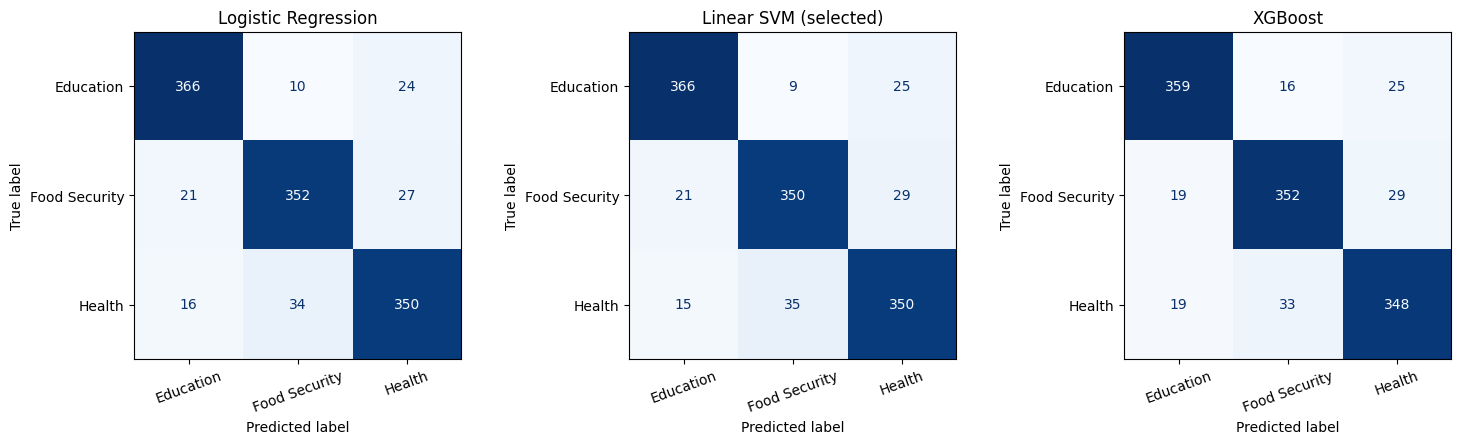

In [5]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4.5))
for ax, (name, m) in zip(np.atleast_1d(axes), models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, m.predict(X_test), display_labels=CLASSES, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name + (' (selected)' if name == SELECTED_NAME else ''))
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, 'confusion_matrices.png'), dpi=150)
plt.show()

## 4. Accuracy by source file
Each class currently comes from one source file, so this equals per-class accuracy. It becomes more informative if a class draws from several files.

In [6]:
df_test['pred'] = le.inverse_transform(y_pred)
df_test['confidence'] = selected.predict_proba(X_test).max(axis=1)
df_test['correct'] = df_test['pred'] == df_test['label']

if 'source' in df_test.columns:
    print(df_test.groupby('source')['correct'].agg(['mean', 'size']).round(3))

                     mean  size
source                         
AFYA_Cleaned.txt    0.875   400
ELIMU_Cleaned.txt   0.915   400
KILIMO_Cleaned.txt  0.875   400


## 5. Resident-style test set
This is the more honest measure. The sentences are first-person and written for evaluation, unlike the formal corpus text.

label
Food Security    30
Health           30
Education        30
Name: count, dtype: int64
               precision    recall  f1-score   support

    Education      0.560     0.467     0.509        30
Food Security      0.867     0.433     0.578        30
       Health      0.500     0.833     0.625        30

     accuracy                          0.578        90
    macro avg      0.642     0.578     0.571        90
 weighted avg      0.642     0.578     0.571        90

Resident macro F1 0.571 vs target 0.8: NOT MET


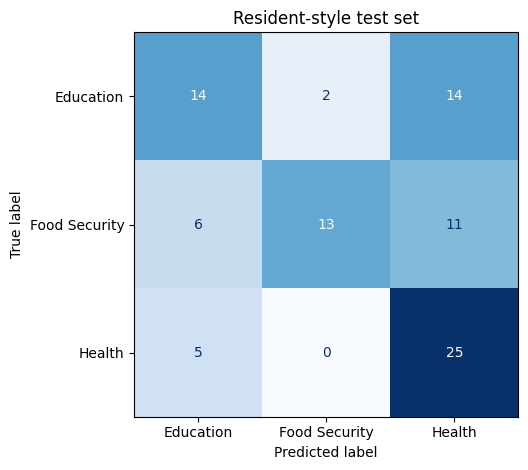


38 errors:
  Hatuna chakula nyumbani tangu jana | true Food Security | predicted Health (0.55)
  Watoto wangu wamelala njaa leo usiku | true Food Security | predicted Health (0.81)
  Tumekula mlo mmoja tu kwa siku nzima | true Food Security | predicted Education (0.41)
  Familia yangu haijapata chakula kwa siku mbili | true Food Security | predicted Education (0.46)
  Mtoto wangu ana njaa na sina cha kumpa | true Food Security | predicted Health (0.61)
  Tunahitaji msaada wa chakula kwa sababu hatuna kitu cha kupika | true Food Security | predicted Education (0.63)
  Jirani yangu na watoto wake hawajala tangu asubuhi | true Food Security | predicted Health (0.64)
  Tunalala bila kula kwa sababu pesa zimeisha | true Food Security | predicted Health (0.47)
  Mama yangu mzee hajala chakula cha kutosha wiki hii | true Food Security | predicted Health (0.55)
  Tunaomba chakula cha msaada kwa sababu njaa imetuzidi | true Food Security | predicted Education (0.42)
  Watoto wanalia kwa njaa n

In [7]:
rt_path = os.path.join(ANN_DIR, 'resident_test.csv')
resident_results = None

if meta['resident_test']['embeddings_file']:
    rt = pd.read_csv(rt_path)
    assert file_md5(rt_path)[:8] == meta['resident_test']['id'], 'resident_test.csv changed. Rerun Notebook 02.'
    X_rt = np.load(os.path.join(PROC_DIR, meta['resident_test']['embeddings_file']))
    y_rt = le.transform(rt['label'])

    rt_proba = selected.predict_proba(X_rt)
    rt['pred'] = le.inverse_transform(rt_proba.argmax(axis=1))
    rt['confidence'] = rt_proba.max(axis=1)

    per_class = rt['label'].value_counts()
    print(per_class)
    if per_class.min() < 25:
        print('WARNING: fewer than 25 sentences in a class. Treat these scores as indicative only.')

    print(classification_report(y_rt, rt_proba.argmax(axis=1), target_names=CLASSES, digits=3, zero_division=0))
    rt_macro_f1 = f1_score(y_rt, rt_proba.argmax(axis=1), average='macro')
    print(f'Resident macro F1 {rt_macro_f1:.3f} vs target {TARGET_F1}:',
          'MET' if rt_macro_f1 >= TARGET_F1 else 'NOT MET')

    ConfusionMatrixDisplay.from_predictions(
        y_rt, rt_proba.argmax(axis=1), display_labels=CLASSES, cmap='Blues', colorbar=False)
    plt.title('Resident-style test set')
    plt.tight_layout()
    plt.savefig(os.path.join(EVAL_DIR, 'resident_confusion_matrix.png'), dpi=150)
    plt.show()

    wrong = rt[rt['pred'] != rt['label']]
    print(f'\n{len(wrong)} errors:')
    for _, r in wrong.iterrows():
        print(f"  {r['sentence']} | true {r['label']} | predicted {r['pred']} ({r['confidence']:.2f})")

    resident_results = {'rows': int(len(rt)), 'macro_f1': float(rt_macro_f1),
                        'accuracy': float((rt['pred'] == rt['label']).mean()),
                        'errors': int(len(wrong))}
elif os.path.exists(rt_path):
    print('resident_test.csv was added after training. Rerun Notebook 02 to embed it.')
else:
    print('resident_test.csv not found. Create it in data/annotated/ and rerun Notebook 02.')

## 6. Confidence and routing threshold
Concerns below the threshold go to manual review instead of a CBO. The threshold is chosen from 5-fold cross-validated predictions on the training partition: the lowest value whose routed predictions reach the target accuracy. The test partition is only used afterwards to report the effect.

 threshold  routed share  routed accuracy
      0.40         0.998            0.891
      0.45         0.988            0.895
      0.50         0.971            0.901
      0.55         0.930            0.916
      0.60         0.886            0.934
      0.65         0.840            0.944
      0.70         0.791            0.954
      0.75         0.734            0.966
      0.80         0.674            0.975
      0.85         0.591            0.983
      0.90         0.475            0.989
      0.95         0.305            0.995

Chosen threshold: 0.5 (proposal assumed 0.60)
Expected calibration error (CV): 0.055


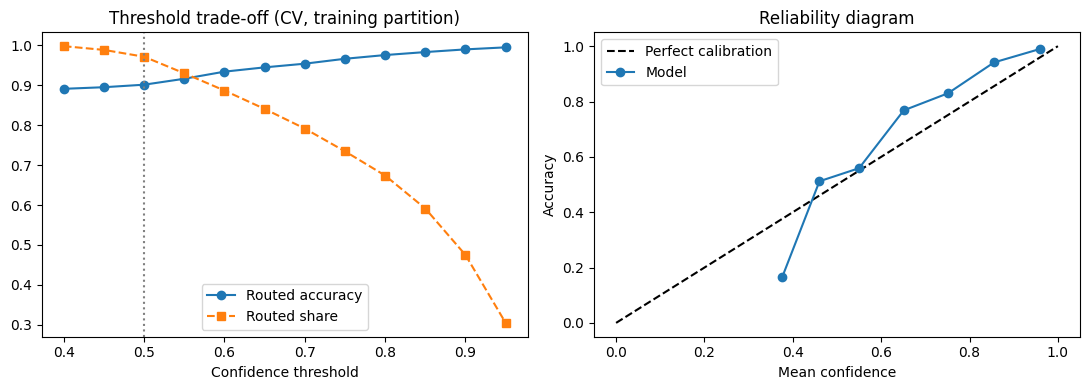


On the test partition at 0.5: routed 97.8%, routed accuracy 0.895, flagged for review 27


In [8]:
TARGET_ROUTED_ACC = 0.90
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_proba = cross_val_predict(clone(selected), X_train, y_train, cv=cv, method='predict_proba')
cv_conf, cv_pred = cv_proba.max(axis=1), cv_proba.argmax(axis=1)

rows = []
for t in np.arange(0.40, 0.96, 0.05):
    routed = cv_conf >= t
    rows.append({'threshold': round(float(t), 2),
                 'routed share': routed.mean(),
                 'routed accuracy': (cv_pred[routed] == y_train[routed]).mean() if routed.any() else np.nan})
threshold_table = pd.DataFrame(rows)
print(threshold_table.round(3).to_string(index=False))

ok = threshold_table[threshold_table['routed accuracy'] >= TARGET_ROUTED_ACC]
if len(ok):
    THRESHOLD = float(ok['threshold'].iloc[0])
else:
    THRESHOLD = float(threshold_table['threshold'].iloc[-1])
    print(f'\nNo threshold reached {TARGET_ROUTED_ACC:.0%}. Using the highest value.')
print(f'\nChosen threshold: {THRESHOLD} (proposal assumed 0.60)')

edges = np.linspace(0, 1, 11)
gaps, weights = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (cv_conf > lo) & (cv_conf <= hi)
    if m.any():
        gaps.append(abs((cv_pred[m] == y_train[m]).mean() - cv_conf[m].mean()))
        weights.append(m.mean())
ece = float(np.average(gaps, weights=weights))
print(f'Expected calibration error (CV): {ece:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(threshold_table['threshold'], threshold_table['routed accuracy'], 'o-', label='Routed accuracy')
ax[0].plot(threshold_table['threshold'], threshold_table['routed share'], 's--', label='Routed share')
ax[0].axvline(THRESHOLD, color='gray', linestyle=':')
ax[0].set_xlabel('Confidence threshold')
ax[0].legend()
ax[0].set_title('Threshold trade-off (CV, training partition)')

correct = (cv_pred == y_train).astype(float)
bins = np.digitize(cv_conf, edges[1:-1])
pts = [(cv_conf[bins == b].mean(), correct[bins == b].mean()) for b in range(10) if (bins == b).any()]
ax[1].plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax[1].plot(*zip(*pts), 'o-', label='Model')
ax[1].set_xlabel('Mean confidence')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[1].set_title('Reliability diagram')
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, 'threshold_and_calibration.png'), dpi=150)
plt.show()

routed_test = df_test['confidence'] >= THRESHOLD
print(f"\nOn the test partition at {THRESHOLD}: routed {routed_test.mean():.1%}, "
      f"routed accuracy {df_test.loc[routed_test, 'correct'].mean():.3f}, "
      f"flagged for review {(~routed_test).sum()}")

## 7. Error analysis

In [9]:
errors = df_test[~df_test['correct']]
print(f'{len(errors)} errors of {len(df_test)} ({len(errors) / len(df_test):.1%})')

if len(errors):
    print('\nMost common confusions (true -> predicted):')
    print(errors.groupby(['label', 'pred']).size().sort_values(ascending=False).head(10))
    print('\nExamples:')
    for _, r in errors.head(10).iterrows():
        print(f"  {r['sentence'][:140]} | true {r['label']} | predicted {r['pred']} ({r['confidence']:.2f})")

df_test.to_csv(os.path.join(EVAL_DIR, 'test_predictions.csv'), index=False, encoding='utf-8')

134 errors of 1200 (11.2%)

Most common confusions (true -> predicted):
label          pred         
Health         Food Security    35
Food Security  Health           29
Education      Health           25
Food Security  Education        21
Health         Education        15
Education      Food Security     9
dtype: int64

Examples:
  aidha jumla ya wataalamu kati ya wamehuisha leseni zao | true Health | predicted Food Security (0.49)
  kuhifadhi usajili wa aina mpya za mimea c | true Education | predicted Food Security (0.83)
  taaluma na huduma za veterinari | true Food Security | predicted Health (0.99)
  frozen lobster whole | true Food Security | predicted Education (0.70)
  matumizi utunzaji wa hesabu fedha iv | true Health | predicted Food Security (0.57)
  kutoka mataifa idadi ya wanariadha karibu walishiriki | true Education | predicted Health (0.79)
  senate inanuiwa kuunda uwakilishi wa viongozi wa kikale na matabaka mbalimbali ya wilaya na pia makundi fulani yenye mahitaji 

## 8. SHAP feature importance
SHAP is applied to the XGBoost model. Its features are the 768 AfroXLMR embedding dimensions, not words, so the plot shows which embedding dimensions influence each class. It does not identify influential Swahili words. Word-level explanations follow in section 9.

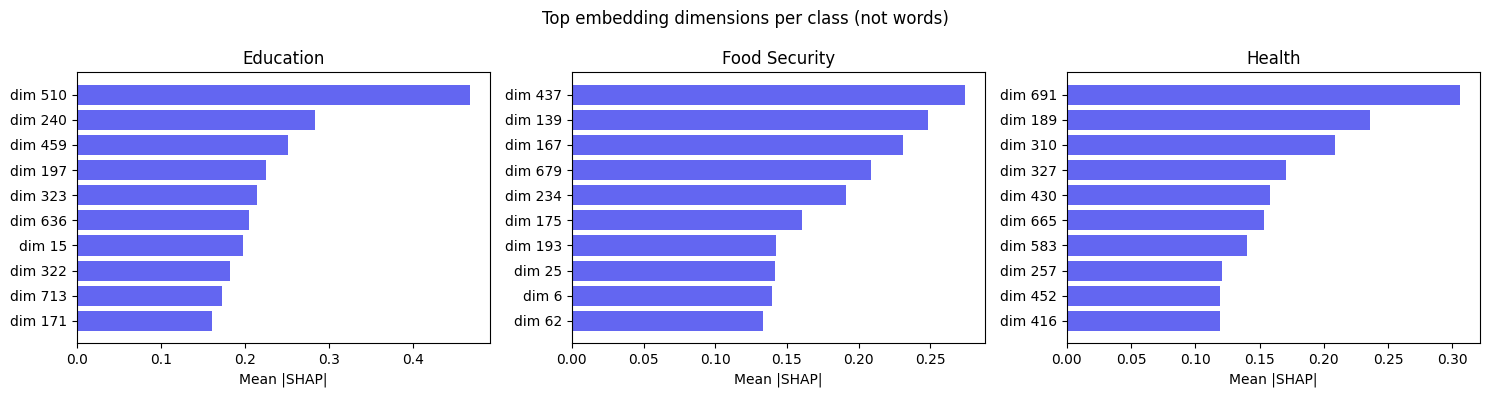

In [10]:
try:
    import shap

    xgb_model = models['XGBoost']
    clf = xgb_model.named_steps['clf'] if hasattr(xgb_model, 'named_steps') else xgb_model
    sample = X_test[:min(300, len(X_test))]

    values = shap.TreeExplainer(clf).shap_values(sample)
    values = np.array(values) if isinstance(values, list) else values
    if values.ndim == 3 and values.shape[-1] == len(CLASSES):
        values = np.transpose(values, (2, 0, 1))
    assert values.shape == (len(CLASSES), len(sample), X_test.shape[1]), values.shape

    fig, axes = plt.subplots(1, len(CLASSES), figsize=(5 * len(CLASSES), 4))
    for ax, k, cls in zip(np.atleast_1d(axes), range(len(CLASSES)), CLASSES):
        mean_abs = np.abs(values[k]).mean(axis=0)
        top = np.argsort(mean_abs)[::-1][:10]
        ax.barh([f'dim {i}' for i in top], mean_abs[top], color='#6366F1')
        ax.invert_yaxis()
        ax.set_title(cls)
        ax.set_xlabel('Mean |SHAP|')
    plt.suptitle('Top embedding dimensions per class (not words)')
    plt.tight_layout()
    plt.savefig(os.path.join(EVAL_DIR, 'shap_embedding_dimensions.png'), dpi=150)
    plt.show()
except Exception as e:
    print('SHAP step skipped:', repr(e))

## 9. Word-level explanations and example predictions
Each word is removed in turn and the drop in confidence for the predicted class is recorded. A large drop means the word supported that prediction. This is an explanation of the model's behaviour, not proof of cause.

In [11]:
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()


def mean_pool(hidden, mask):
    mask = mask.unsqueeze(-1).float()
    return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)


def embed(texts, batch_size=32):
    texts = [normalise(t) if NORMALISE else str(t) for t in texts]
    out = []
    for i in range(0, len(texts), batch_size):
        batch = tokenizer(texts[i:i + batch_size], return_tensors='pt', padding=True,
                          truncation=True, max_length=128).to(device)
        with torch.no_grad():
            hidden = encoder(**batch).last_hidden_state
        out.append(mean_pool(hidden, batch['attention_mask']).cpu().numpy())
    return np.vstack(out)

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [12]:
def explain(sentence):
    words = sentence.split()
    variants = [sentence] + [' '.join(w for j, w in enumerate(words) if j != i)
                             for i in range(len(words)) if len(words) > 1]
    proba = selected.predict_proba(embed(variants))
    k = int(proba[0].argmax())
    drops = proba[0, k] - proba[1:, k] if len(variants) > 1 else []
    ranked = sorted(zip(words, drops), key=lambda x: -abs(x[1]))
    return CLASSES[k], float(proba[0, k]), ranked


examples = [
    'Watoto wetu wanalala njaa kila usiku',
    'Mama ana kifua kikuu na hospitali iko mbali',
    'Mtoto wangu ameacha shule kwa sababu ya ada',
    'Mtoto wangu ni mgonjwa na hatuna chakula nyumbani',
    'Kuna wezi wanaotisha watu usiku',
    'Nyumba yetu imebomoka kwa mvua',
    'abc xyz',
]

example_rows = []
for s in examples:
    category, conf, ranked = explain(s)
    status = 'routed' if conf >= THRESHOLD else 'flagged for review'
    print(f'\n{s}\n  -> {category} ({conf:.2f}), {status}')
    print('  influential words:', ', '.join(f'{w} ({d:+.2f})' for w, d in ranked[:3]))
    example_rows.append({'sentence': s, 'category': category, 'confidence': round(conf, 3), 'status': status})


Watoto wetu wanalala njaa kila usiku
  -> Health (0.78), routed
  influential words: Watoto (+0.41), njaa (+0.14), wanalala (+0.03)

Mama ana kifua kikuu na hospitali iko mbali
  -> Health (0.64), routed
  influential words: hospitali (+0.38), kifua (-0.32), ana (-0.31)

Mtoto wangu ameacha shule kwa sababu ya ada
  -> Education (0.74), routed
  influential words: shule (+0.18), sababu (+0.10), ya (+0.08)

Mtoto wangu ni mgonjwa na hatuna chakula nyumbani
  -> Health (0.77), routed
  influential words: mgonjwa (+0.42), na (-0.13), wangu (-0.08)

Kuna wezi wanaotisha watu usiku
  -> Education (0.55), routed
  influential words: wanaotisha (+0.53), Kuna (+0.52), watu (+0.31)

Nyumba yetu imebomoka kwa mvua
  -> Education (0.48), flagged for review
  influential words: yetu (-0.27), imebomoka (-0.27), mvua (-0.20)

abc xyz
  -> Health (0.74), routed
  influential words: xyz (+0.54), abc (+0.52)


## 10. Save configuration and conclusions
`model_config.json` holds the settings the backend must reuse at prediction time.

In [13]:
config = {
    'embedding_model': MODEL_NAME,
    'pooling': meta['pooling'],
    'normalise': NORMALISE,
    'max_length': 128,
    'classes': CLASSES,
    'selected_model': SELECTED_NAME,
    'confidence_threshold': THRESHOLD,
}
with open(os.path.join(MODELS_DIR, 'model_config.json'), 'w') as f:
    json.dump(config, f, indent=2)

summary = {
    'run_id': meta['run_id'],
    'selected_model': SELECTED_NAME,
    'test': {'rows': int(len(X_test)), 'accuracy': float(accuracy_score(y_test, y_pred)),
             'macro_f1': float(test_macro_f1), 'target_met': bool(test_macro_f1 >= TARGET_F1)},
    'all_models': model_table.round(4).to_dict(orient='records'),
    'resident_test': resident_results,
    'threshold': {'chosen': THRESHOLD, 'target_routed_accuracy': TARGET_ROUTED_ACC, 'cv_ece': round(ece, 4)},
    'examples': example_rows,
}
with open(os.path.join(EVAL_DIR, 'evaluation_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

print('Saved evaluation summary and model_config.json')
print('\nLimitations to state in Chapter 5:')
print('1. Training text comes from formal corpus files, not resident speech.')
print('2. Each sentence gets one label. Multi-concern sentences get the dominant category only.')
print('3. Concerns outside the current categories are forced into one of them.')
print('4. SHAP dimensions are embeddings, not words.')
print('5. Whisper transcription errors are not yet part of this evaluation.')

Saved evaluation summary and model_config.json

Limitations to state in Chapter 5:
1. Training text comes from formal corpus files, not resident speech.
2. Each sentence gets one label. Multi-concern sentences get the dominant category only.
3. Concerns outside the current categories are forced into one of them.
4. SHAP dimensions are embeddings, not words.
5. Whisper transcription errors are not yet part of this evaluation.
